In [1]:
import os
import sys
import utils
import random
import numpy as np
import pandas as pd
import seaborn as sn
import nivapy3 as nivapy
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.lines as mlines 
import matplotlib.dates as mdates
import cartopy.feature as cfeature
from sklearn.preprocessing import StandardScaler
from matplotlib.backends.backend_pdf import PdfPages

sys.path.append("..")
plt.style.use("ggplot")

In [2]:
def plot_map(df, plot_variables='all'):
    fig = plt.figure(figsize=(25, 30))

    # Create a GeoAxes in the tile's projection
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

    # Add coastlines and country borders
    ax.coastlines(linewidth=2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=2)

    # Define a color map for the parameters
    colormap = {'TN': 'orange', 'TP': 'blue', 'TOC': 'green'}

    # Plot TN
    if plot_variables == 'all' or plot_variables == 'TN':
        ax.scatter(df['lon'][df['N-TOT_µg_l'] > 5000], df['lat'][df['N-TOT_µg_l'] > 5000], color=colormap['TN'], edgecolor='white', s=200, transform=ccrs.PlateCarree(), label='TN > 5000 µg/L')

    # Plot TP
    if plot_variables == 'all' or plot_variables == 'TP':
        ax.scatter(df['lon'][df['P-TOT_µg_l'] > 3000], df['lat'][df['P-TOT_µg_l'] > 3000], color=colormap['TP'], edgecolor='white', s=200, transform=ccrs.PlateCarree(), label='TP > 3000 µg/L')

    # Plot TOC
    if plot_variables == 'all' or plot_variables == 'TOC':
        ax.scatter(df['lon'][df['TOC_mg_l'] > 40], df['lat'][df['TOC_mg_l'] > 40], color=colormap['TOC'], edgecolor='white', s=200, transform=ccrs.PlateCarree(), label='TOC > 40 mg/L')

    # Add gridlines with labels
    gl = ax.gridlines(draw_labels=True, alpha=0)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 25}
    gl.ylabel_style = {'size': 25}

    # Set the extent to show Norway
    ax.set_extent([4, 32, 57, 72], crs=ccrs.PlateCarree())

    ax.set_facecolor('white')

    # Create legend
    legend_handles = [mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=10, label=label) for label, color in colormap.items() if plot_variables == 'all' or plot_variables == label]
    legend = ax.legend(handles=legend_handles, bbox_to_anchor=(1, 1), loc='upper left', title='Parameters', edgecolor='black', fontsize='xx-large', title_fontsize='20')
    legend.get_frame().set_facecolor('white')
    legend.get_frame().set_edgecolor('black')
    legend.get_frame().set_linewidth(2)

    # Add borders around the axes
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(2)

    plt.show()

# Check rivers with suspicious values 
Leah - For TN, TP and TOC, I would expect the absolute MAXIMUM plausible values to be:
* TN: 10 mg/l. But anything over 5 mg/l I would be suspicious of
* TP: 5 mg/l, but suspicious over 3 mg/l
* TOC: 100 mg/l, suspicious over 40-60 mg/l for rivers, and anything above 30'ish need to be a small forest stream...

### 1. Sites with TN, TP, and TOC above thresholds

In [4]:
df_R = pd.read_csv("../data/cleaned/water_chemistry/ai_wc_outliers_flagged_rivers.csv")

# Extract year from sampling time
df_R['SamplingTime'] = pd.to_datetime(df_R['SamplingTime'])
df_R['Year'] = df_R['SamplingTime'].dt.year

df_R.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 248568 entries, 0 to 248567
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   WaterLocationID       248568 non-null  int64         
 1   WaterLocationCode     248568 non-null  object        
 2   Name                  248568 non-null  object        
 3   ActivityID            248568 non-null  object        
 4   ActivityName          248568 non-null  object        
 5   MediumID              248568 non-null  object        
 6   WaterCategory         248568 non-null  object        
 7   SamplingTime          248568 non-null  datetime64[ns]
 8   lon                   248568 non-null  float64       
 9   lat                   248568 non-null  float64       
 10  UpperDepth            248568 non-null  float64       
 11  LowerDepth            248568 non-null  float64       
 12  N-TOT_µg_l            205146 non-null  float64       
 13 

In [5]:
# Filter the dataframe based on the conditions
filtered_df_i = df_R[(df_R['N-TOT_µg_l'] > 5000) & (df_R['P-TOT_µg_l'] > 3000) & (df_R['TOC_mg_l'] > 40)]

# Get the unique water location codes and their count
unique_codes = list(filtered_df_i['WaterLocationCode'].unique())
count_unique_codes = len(unique_codes)

print("Number of sites with suspicious data:", count_unique_codes)
print(" ")
print("Water Location Codes with suspicious data:\n", unique_codes)

Number of sites with suspicious data: 13
 
Water Location Codes with suspicious data:
 ['002-50944', '002-52001', '002-81363', '002-97207', '003-30664', '013-28499', '015-95153', '038-31174', '083-97286', '121-96702', '180-88658', '224-96606', '224-96611']


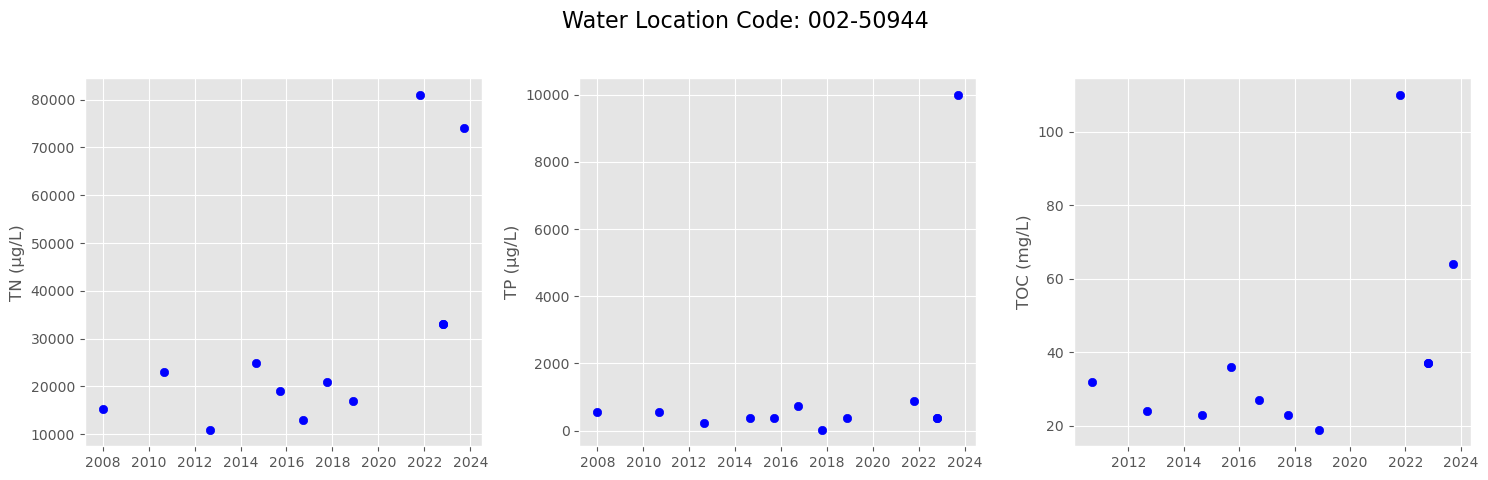

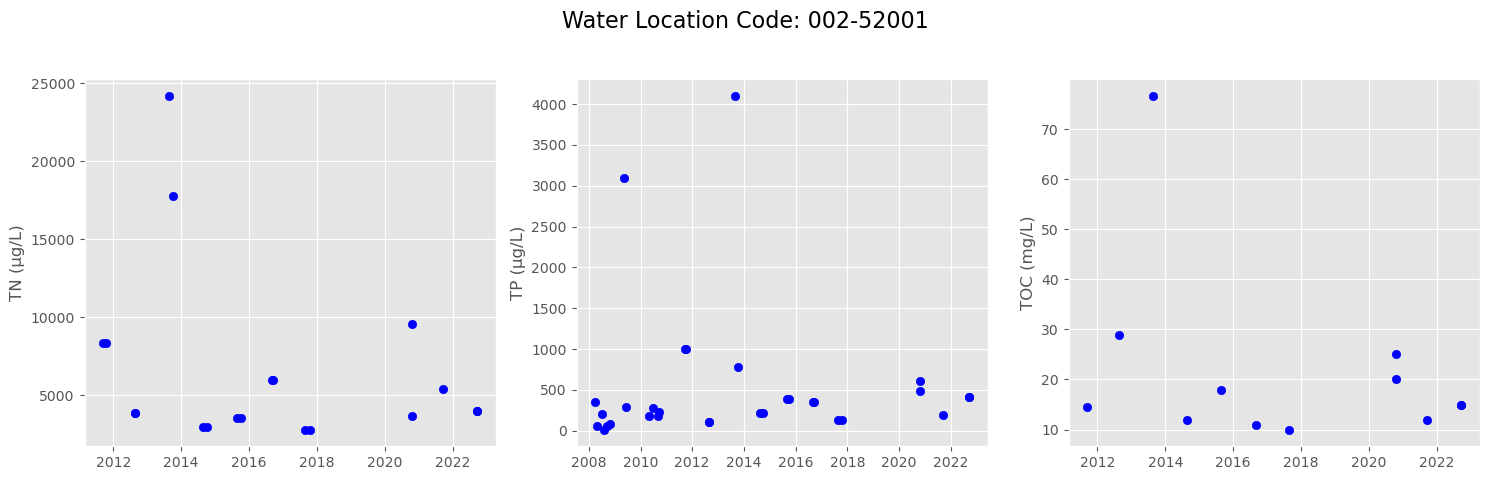

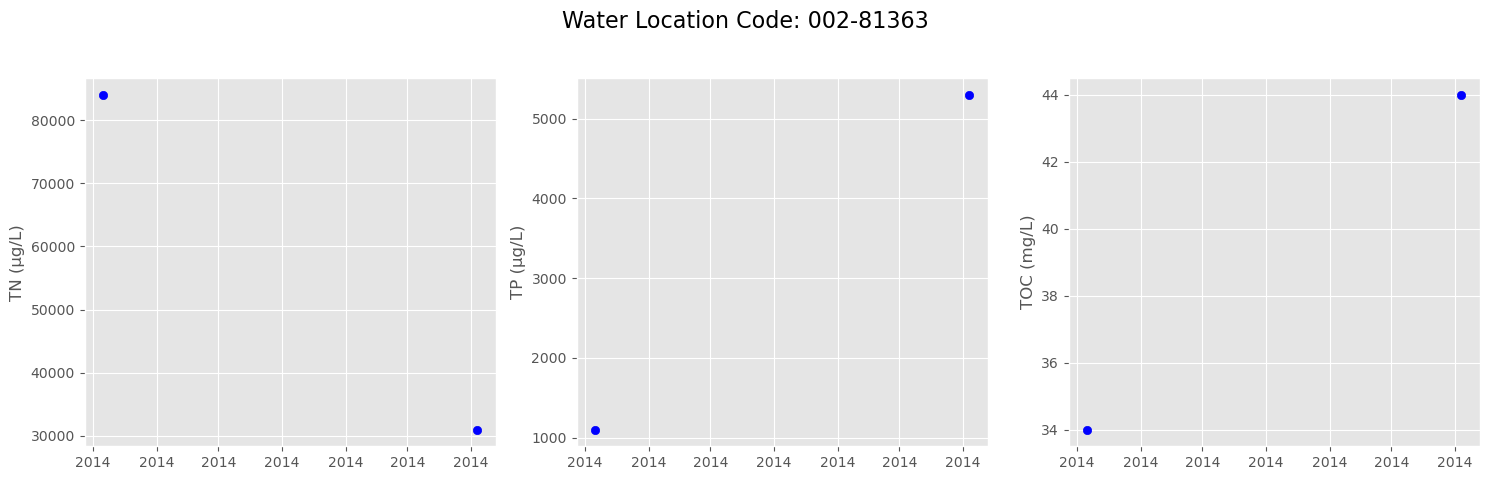

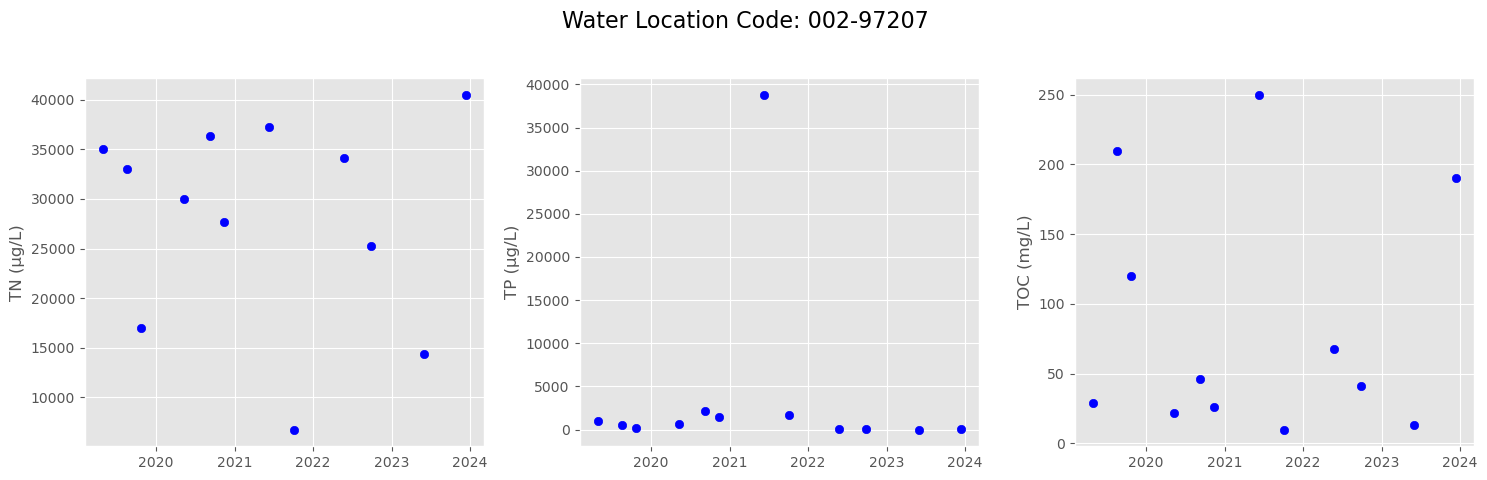

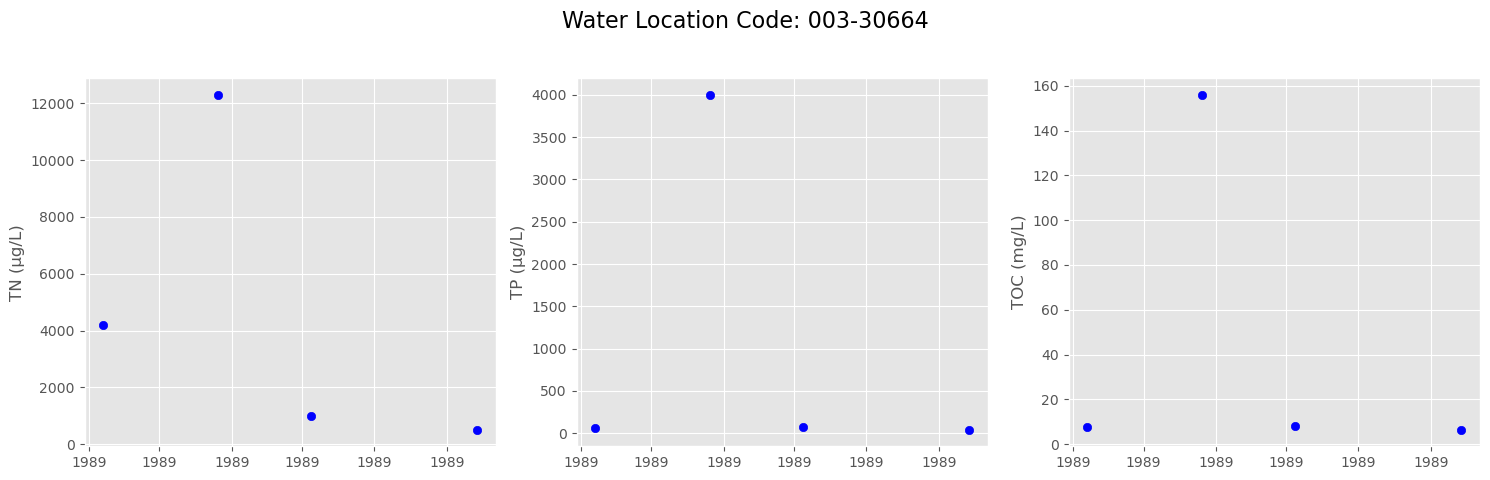

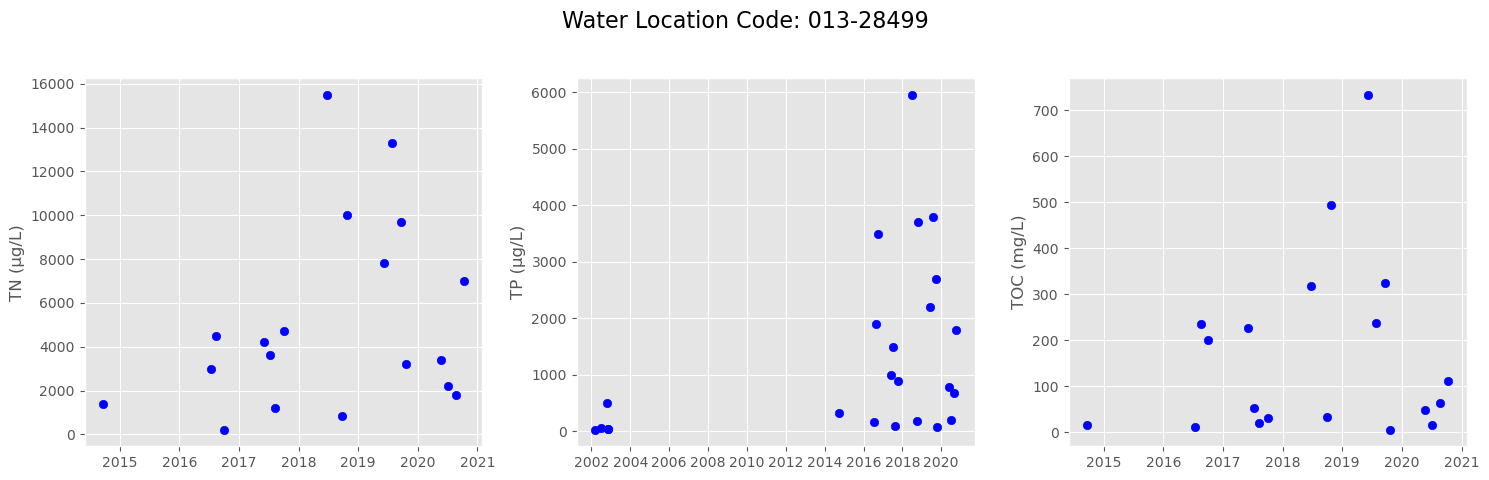

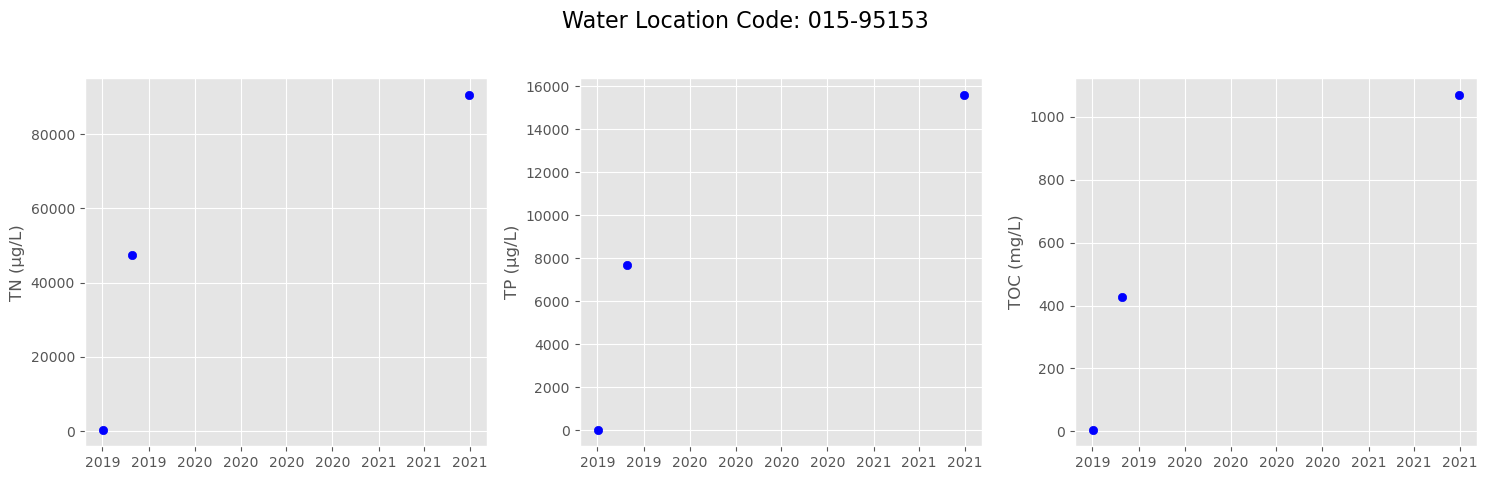

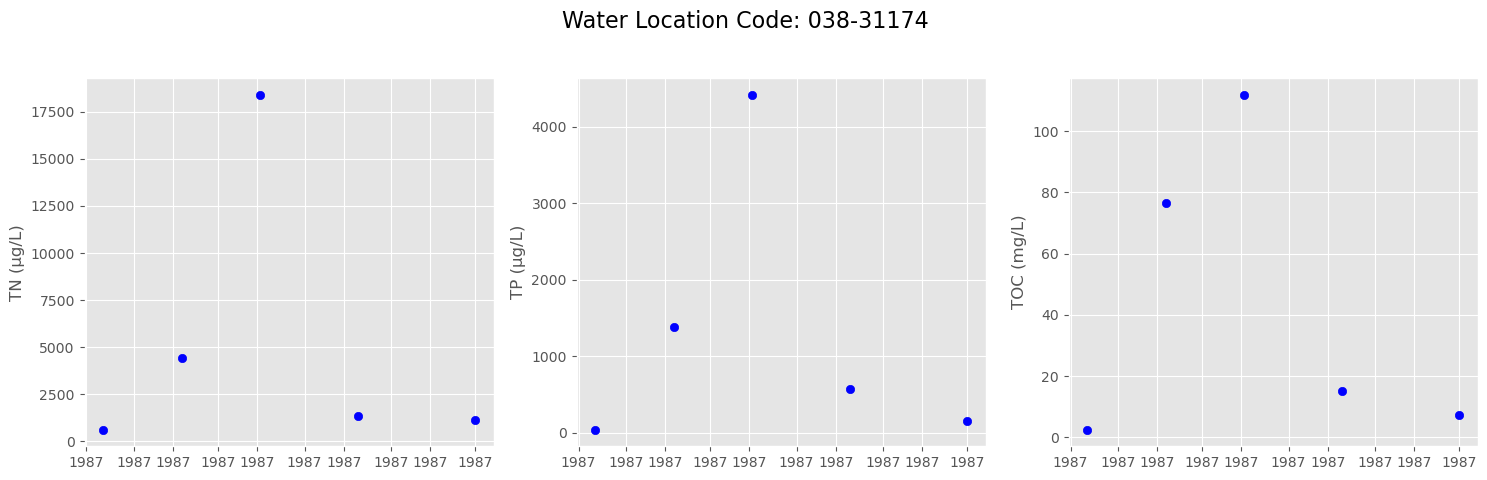

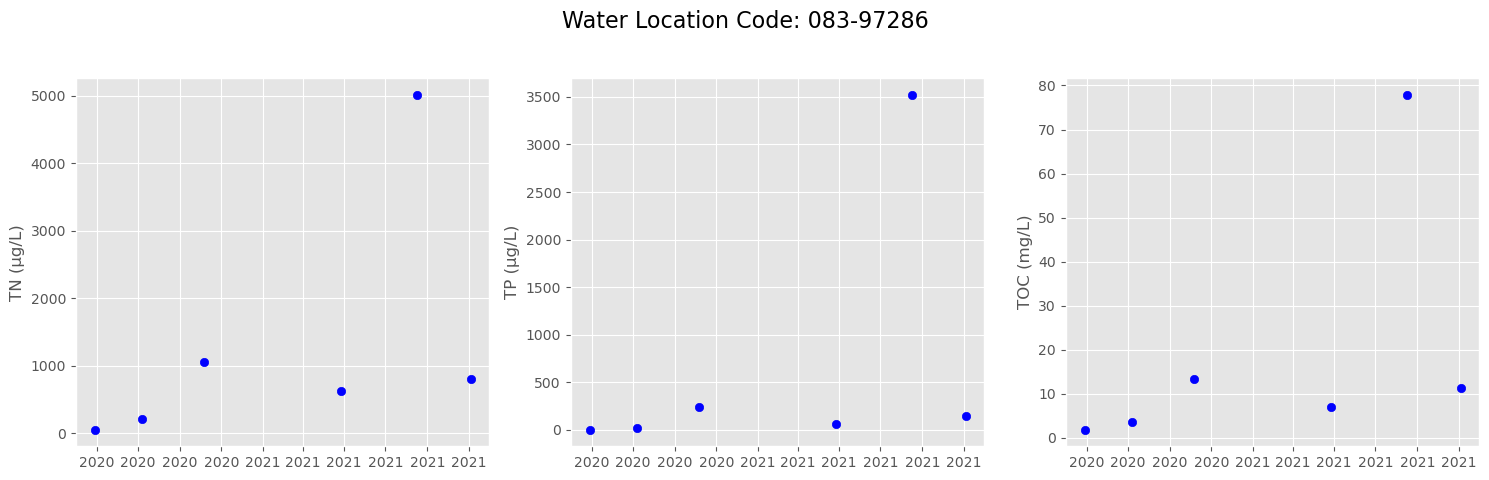

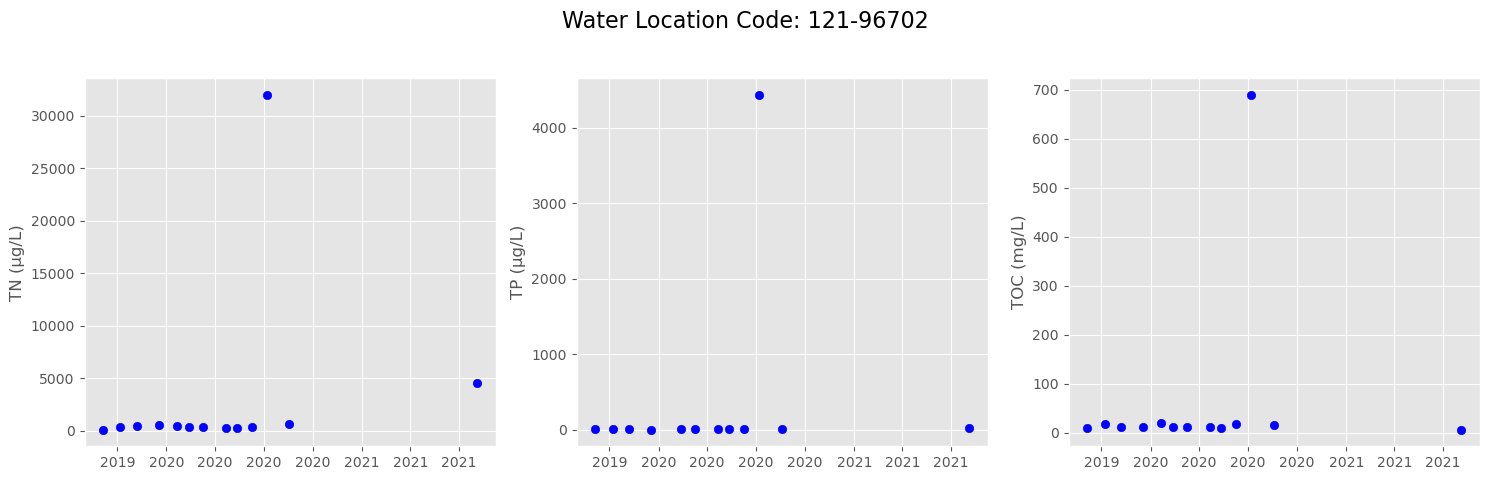

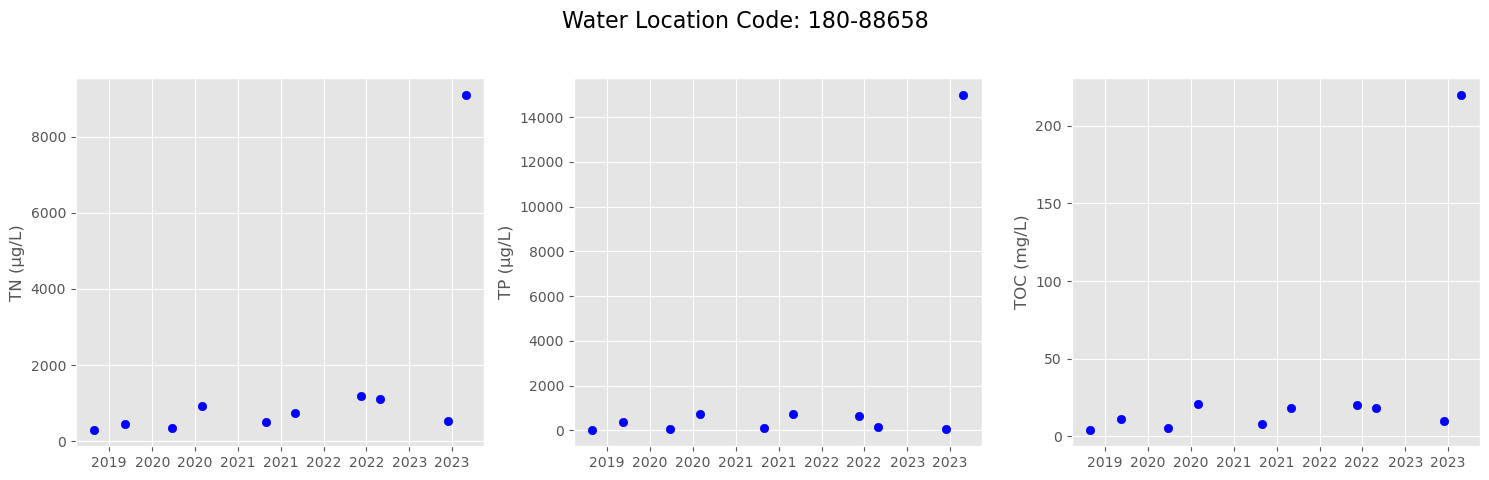

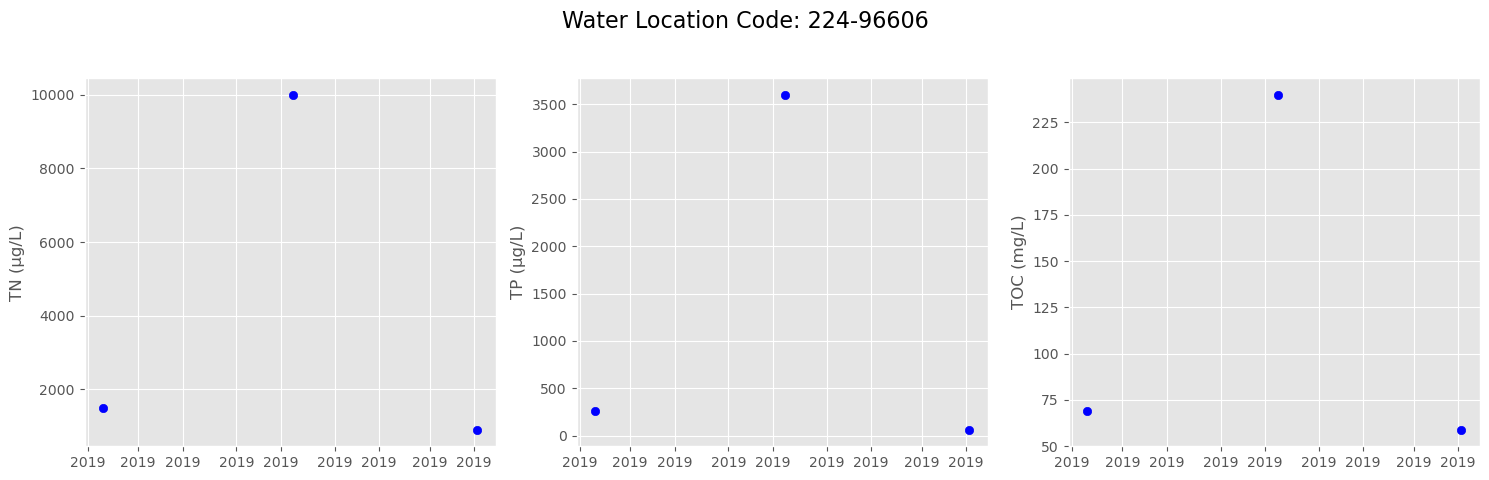

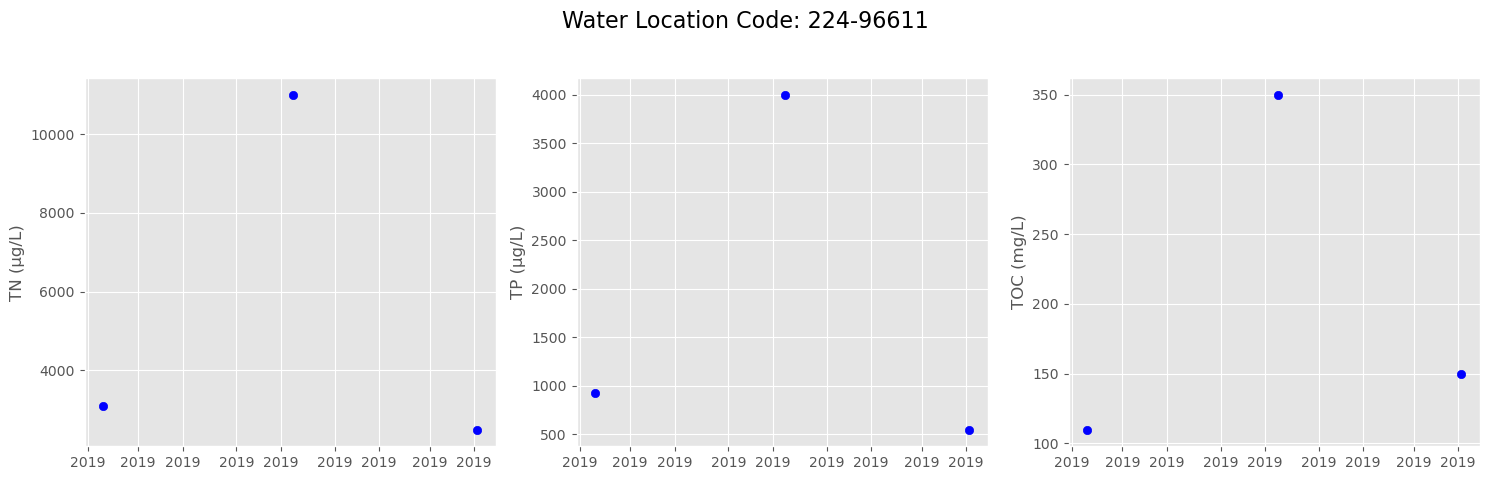

In [6]:
# Create a PDF file to save the plots
with PdfPages('../plots/sites_with_suspicious_values_all_vars.pdf') as pdf:
    for code in unique_codes:
        site_data = df_R[df_R['WaterLocationCode'] == code]
        
        fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
        fig.suptitle(f'Water Location Code: {code}', fontsize=16)
        
        # Plot TN
        axes[0].scatter(site_data['SamplingTime'], site_data['N-TOT_µg_l'], marker='o', color = "blue")
        axes[0].set_ylabel('TN (µg/L)')
        axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        
        # Plot TP
        axes[1].scatter(site_data['SamplingTime'], site_data['P-TOT_µg_l'], marker='o', color = "blue")
        axes[1].set_ylabel('TP (µg/L)')
        axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        
        # Plot TOC
        axes[2].scatter(site_data['SamplingTime'], site_data['TOC_mg_l'], marker='o', color = "blue")
        axes[2].set_ylabel('TOC (mg/L)')
        axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        
        # Adjust layout and save the figure to the PDF
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        pdf.savefig(fig)
        plt.show(fig)

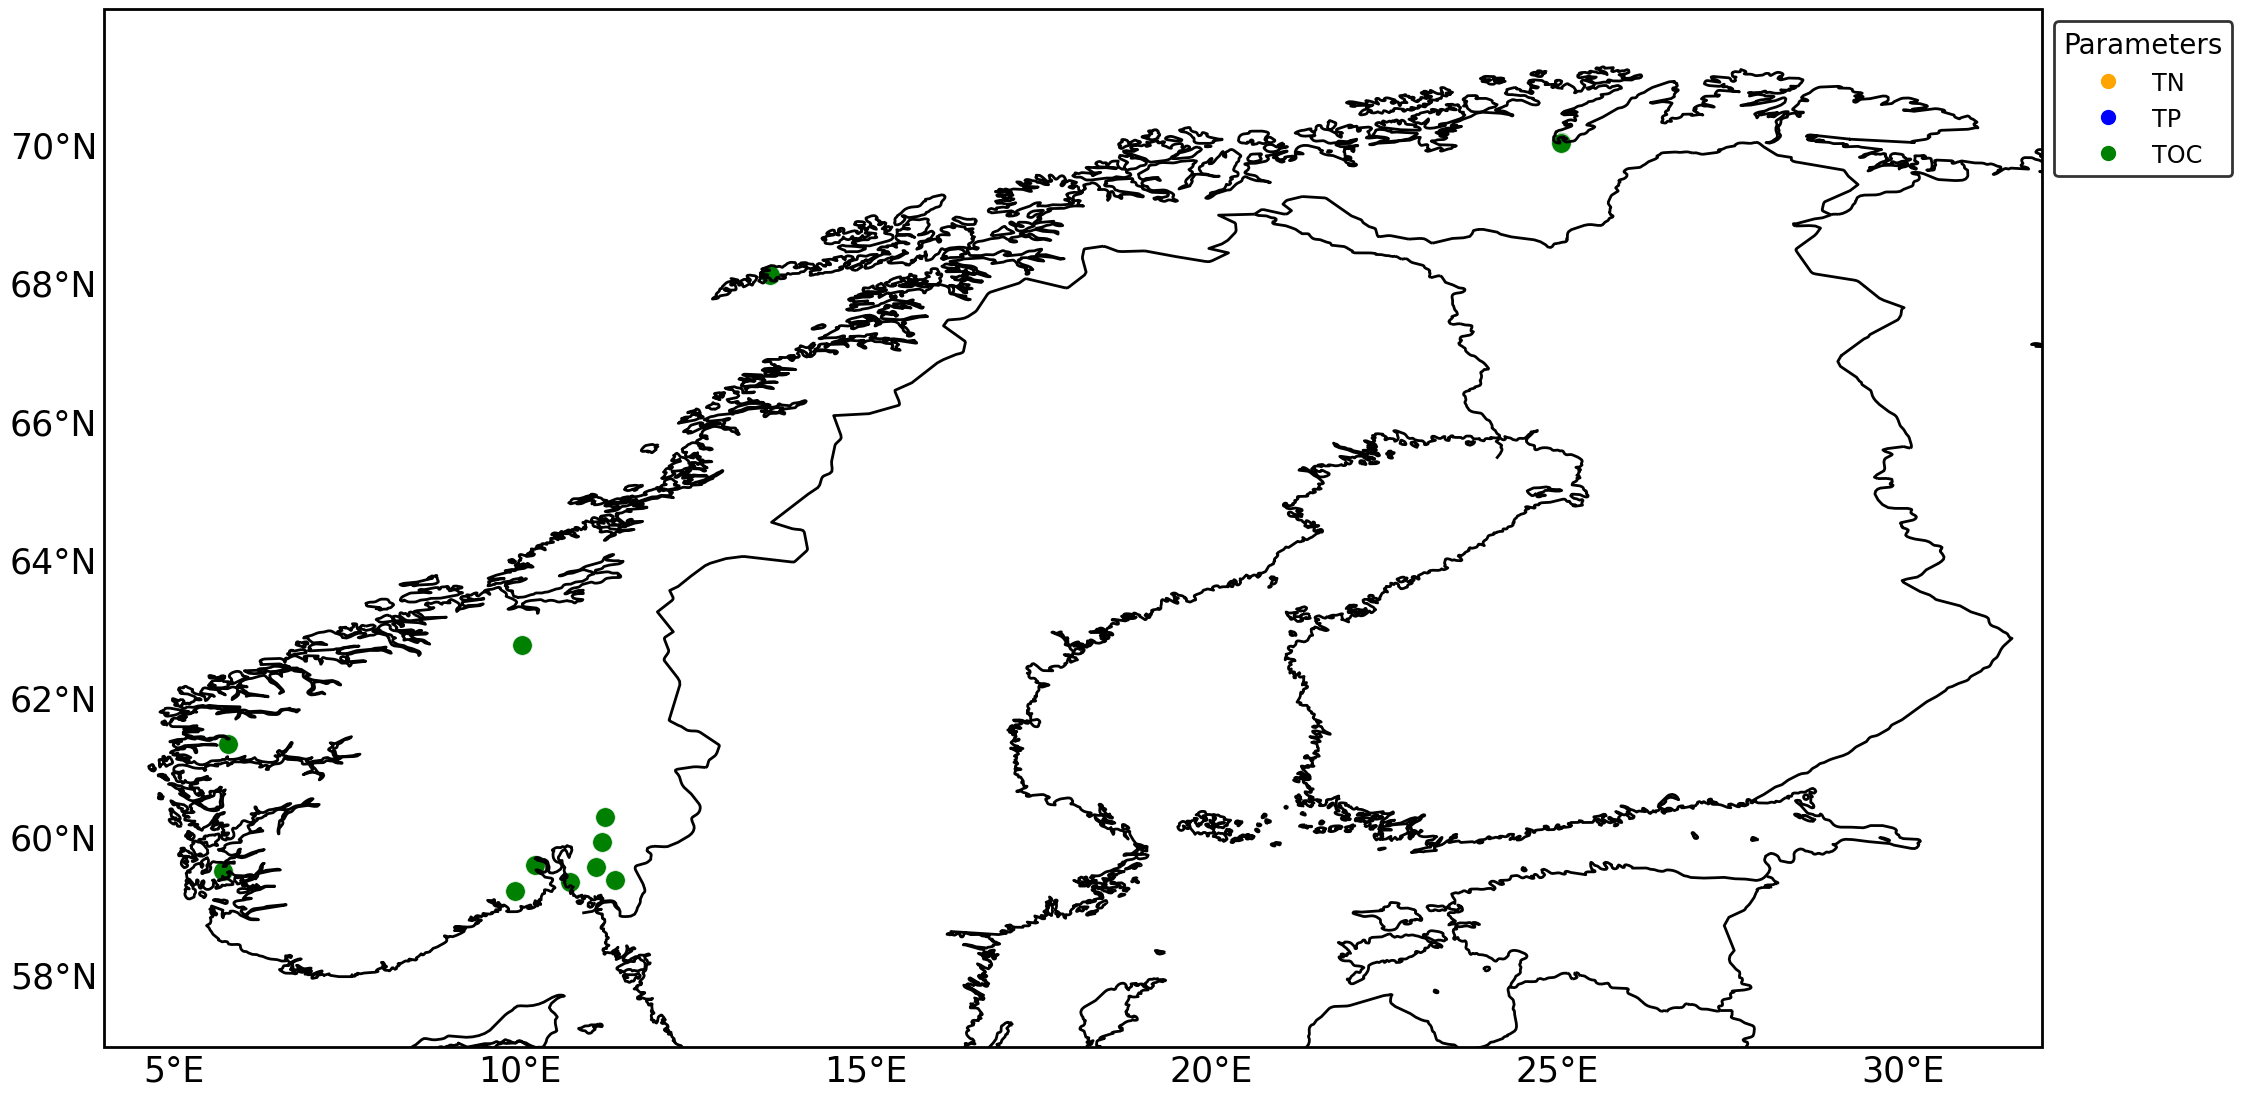

In [7]:
plot_map(filtered_df_i, plot_variables='all')

### 2. Sites with TN above thresholds

In [8]:
# Filter the dataframe based on the conditions
filtered_df_ii = df_R[(df_R['N-TOT_µg_l'] > 5000) & df_R['N-TOT_µg_l'].notna()]

# Get the unique water location codes and their count
unique_codes_ii = list(filtered_df_ii['WaterLocationCode'].unique())
count_unique_codes_ii = len(unique_codes_ii)

print("Number of sites with suspicious data:", count_unique_codes_ii)
print(" ")
print("Water Location Codes with suspicious data:\n", unique_codes_ii)

Number of sites with suspicious data: 1045
 
Water Location Codes with suspicious data:
 ['001-28727', '001-28728', '001-28940', '001-30683', '001-30732', '001-51053', '001-51057', '001-51064', '001-61149', '001-61963', '001-63074', '001-81708', '001-81712', '002-102145', '002-102924', '002-105975', '002-105981', '002-107559', '002-108251', '002-111468', '002-111469', '002-112289', '002-112297', '002-112298', '002-112299', '002-112300', '002-112332', '002-112469', '002-112473', '002-112478', '002-112479', '002-112483', '002-114449', '002-27864', '002-28106', '002-28191', '002-28251', '002-28378', '002-28412', '002-28949', '002-28960', '002-28963', '002-29417', '002-29659', '002-29666', '002-30575', '002-30576', '002-30584', '002-30586', '002-30589', '002-30590', '002-30591', '002-30593', '002-30601', '002-30602', '002-30603', '002-30604', '002-30621', '002-30643', '002-30671', '002-30714', '002-30751', '002-31062', '002-31080', '002-31091', '002-31103', '002-31104', '002-39348', '002-3

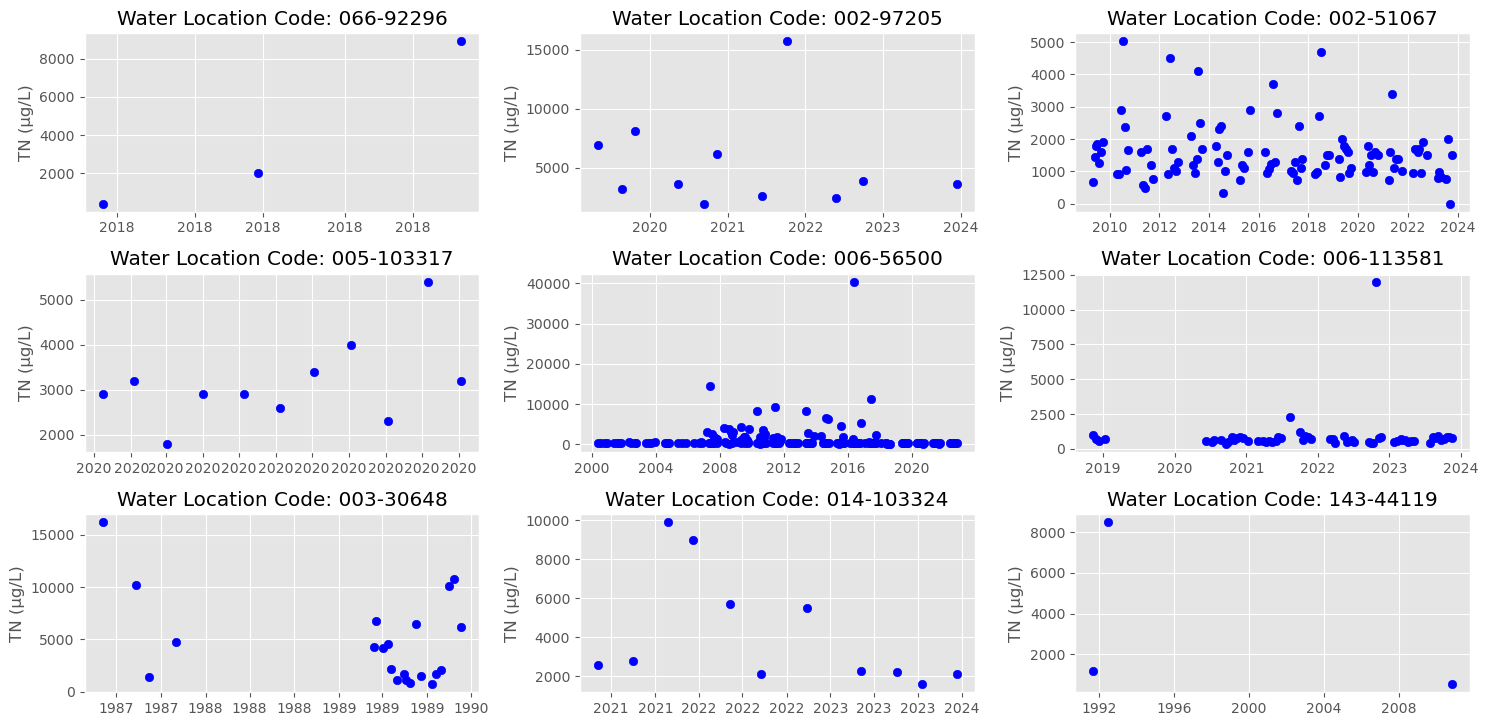

In [9]:
# Define a random list of WaterLocationCode 
random_sites = np.random.choice(unique_codes_ii, 9, replace=False)

with PdfPages('../plots/timeseries_plots_suspicious_tn.pdf') as pdf:
    # Create a figure with 2 columns and 3 rows
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 8))
       
    # Flatten the axes array for easy iteration
    axes = axes.flatten()
    
    # Iterate over each randomly selected WaterLocationCode
    for i, code in enumerate(random_sites):
        site_data = df_R[df_R['WaterLocationCode'] == code]
        
        # Plot TN
        axes[i].scatter(site_data['SamplingTime'], site_data['N-TOT_µg_l'], marker='o', color='blue')
        axes[i].set_title(f'Water Location Code: {code}')
        axes[i].set_ylabel('TN (µg/L)')
        axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    # Adjust layout and save the figure to the PDF
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    pdf.savefig(fig)
    plt.show(fig)

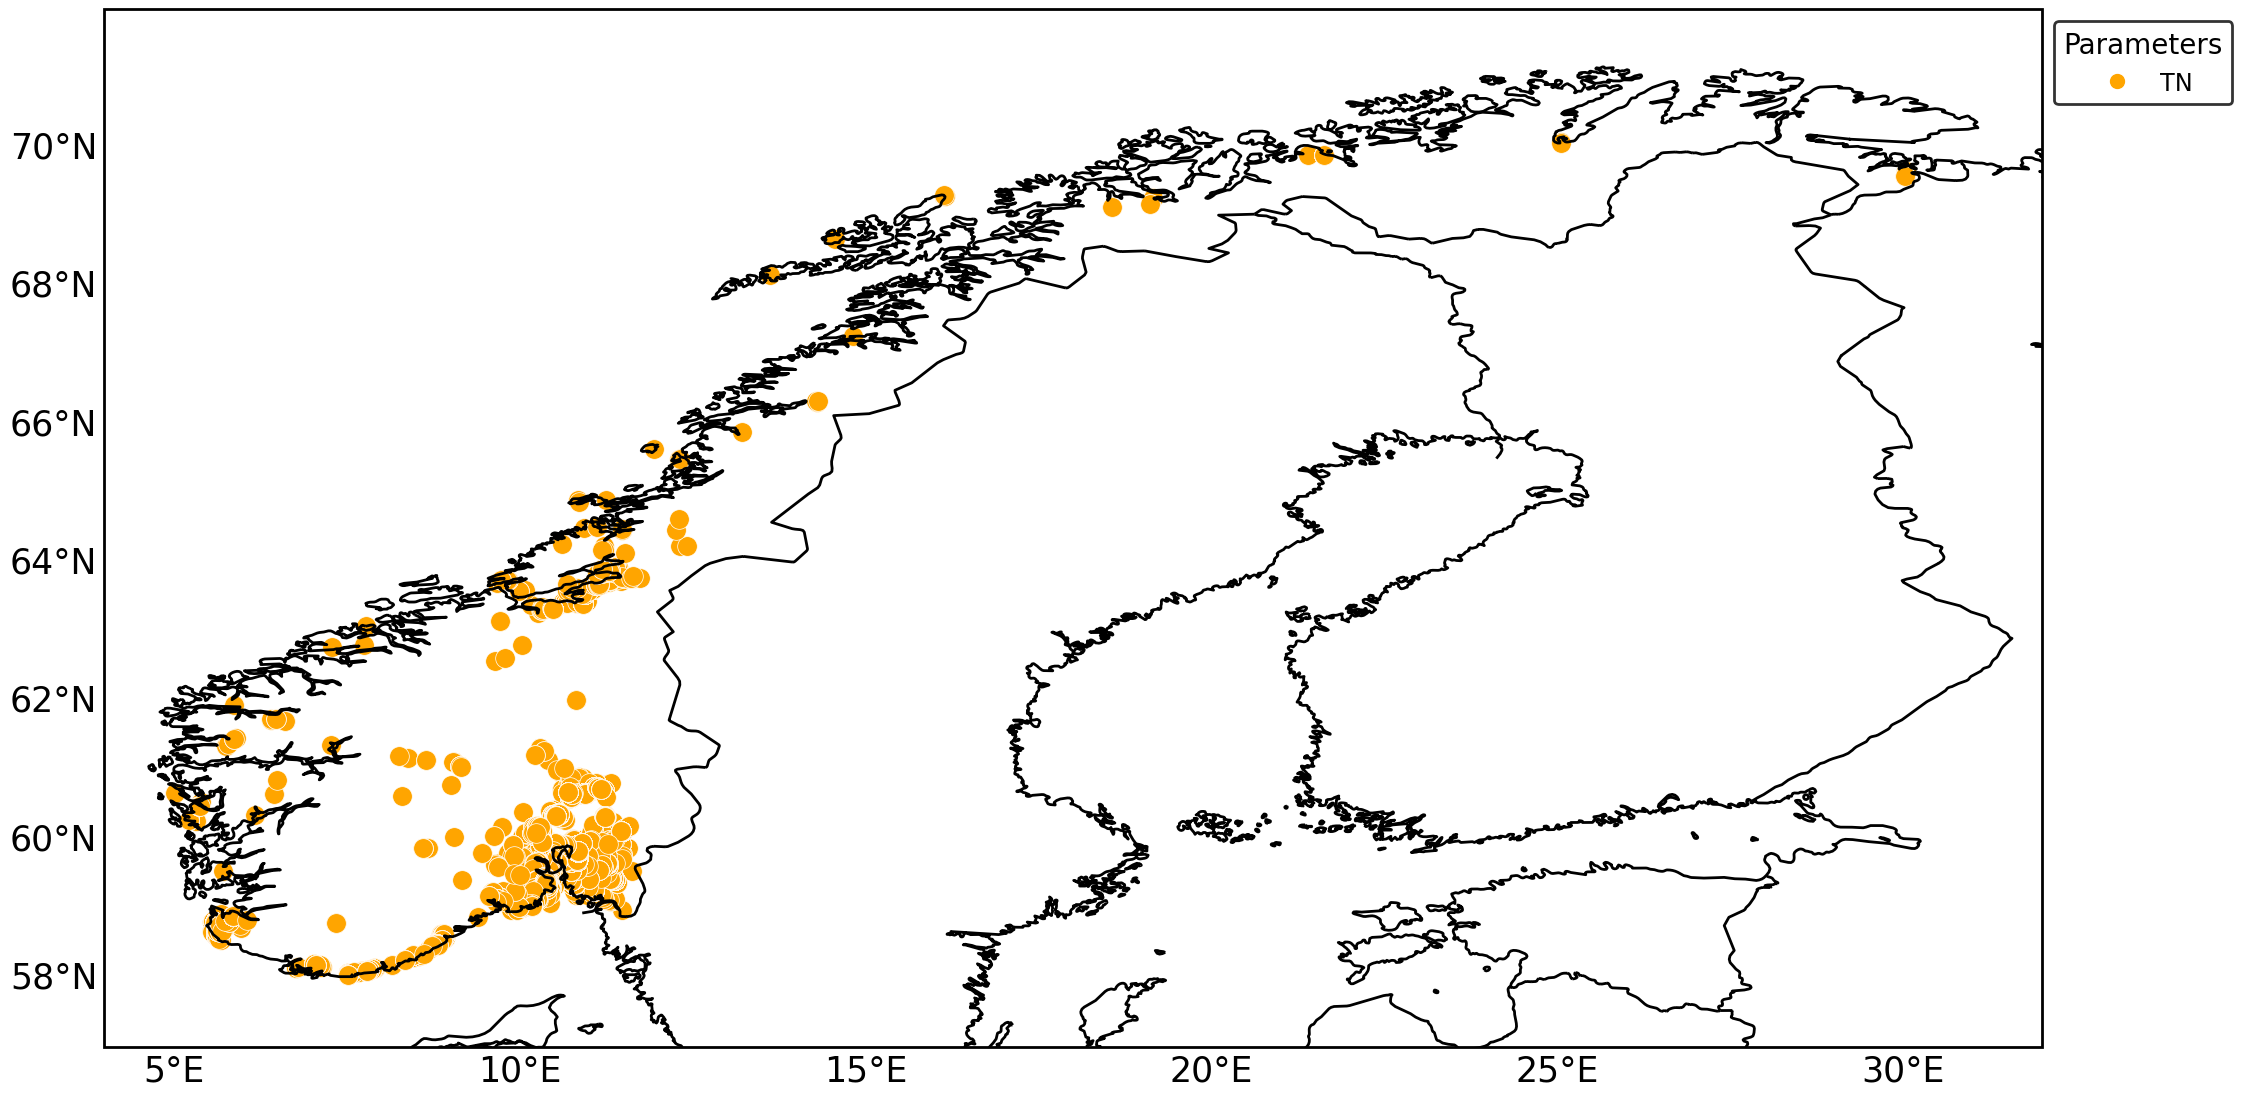

In [10]:
plot_map(filtered_df_ii, plot_variables='TN')

### 3. Sites with TP above thresholds

In [11]:
# Filter the dataframe based on the conditions
filtered_df_iii = df_R[(df_R['P-TOT_µg_l'] > 3000) & df_R['P-TOT_µg_l'].notna()]

# Get the unique water location codes and their count
unique_codes_iii = list(filtered_df_iii['WaterLocationCode'].unique())
count_unique_codes_iii = len(unique_codes_iii)

print("Number of sites with suspicious data:", count_unique_codes_iii)
print(" ")
print("Water Location Codes with suspicious data:\n", unique_codes_iii)

Number of sites with suspicious data: 83
 
Water Location Codes with suspicious data:
 ['002-29666', '002-30576', '002-30671', '002-50857', '002-50944', '002-52001', '002-56279', '002-56282', '002-79784', '002-81363', '002-84408', '002-87768', '002-97207', '003-30664', '003-30752', '003-59330', '003-64443', '004-39369', '004-64214', '004-64215', '004-64237', '005-28244', '005-28248', '005-42446', '005-42450', '005-56286', '007-101735', '007-51734', '008-87633', '010-28686', '011-102463', '011-116011', '011-116013', '011-28689', '011-28690', '012-105375', '012-113638', '012-58650', '012-83299', '012-92624', '012-92625', '012-94376', '013-28499', '014-101777', '014-103098', '014-64238', '015-51131', '015-51132', '015-83889', '015-95153', '015-98401', '016-31599', '019-56289', '028-56288', '038-31174', '066-92296', '083-97286', '089-97490', '110-92528', '110-92530', '110-92531', '110-92532', '121-96702', '122-105432', '122-113109', '123-89749', '123-89766', '123-89823', '125-29627', '125-

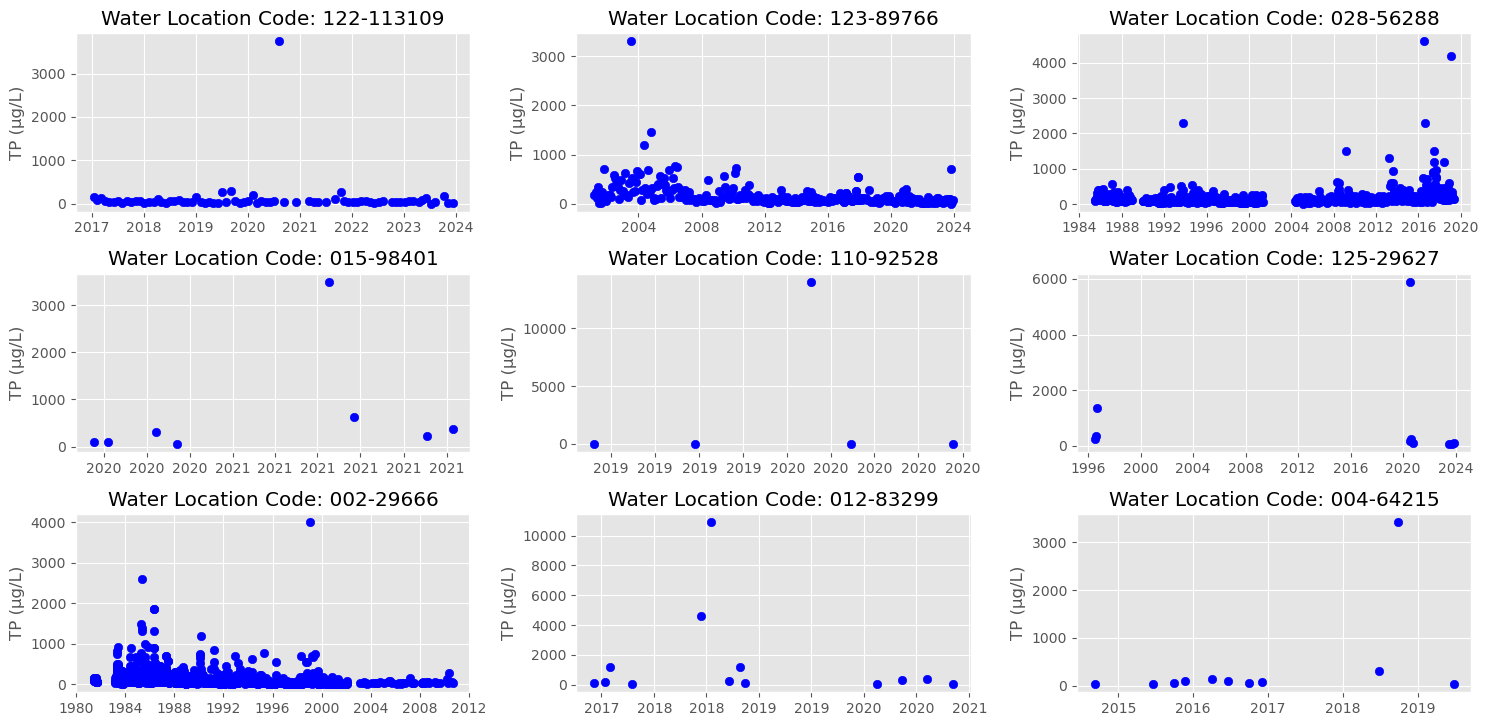

In [12]:
## Define a random list of WaterLocationCode
random_sites = np.random.choice(unique_codes_iii, 9, replace=False)

with PdfPages('../plots/timeseries_plots_suspicious_tp.pdf') as pdf:
    # Create a figure with 2 columns and 3 rows
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 8))
       
    # Flatten the axes array for easy iteration
    axes = axes.flatten()
    
    # Iterate over each randomly selected WaterLocationCode
    for i, code in enumerate(random_sites):
        site_data = df_R[df_R['WaterLocationCode'] == code]
        
        # Plot TN
        axes[i].scatter(site_data['SamplingTime'], site_data['P-TOT_µg_l'], marker='o', color='blue')
        axes[i].set_title(f'Water Location Code: {code}')
        axes[i].set_ylabel('TP (µg/L)')
        axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    # Adjust layout and save the figure to the PDF
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    pdf.savefig(fig)
    plt.show(fig)

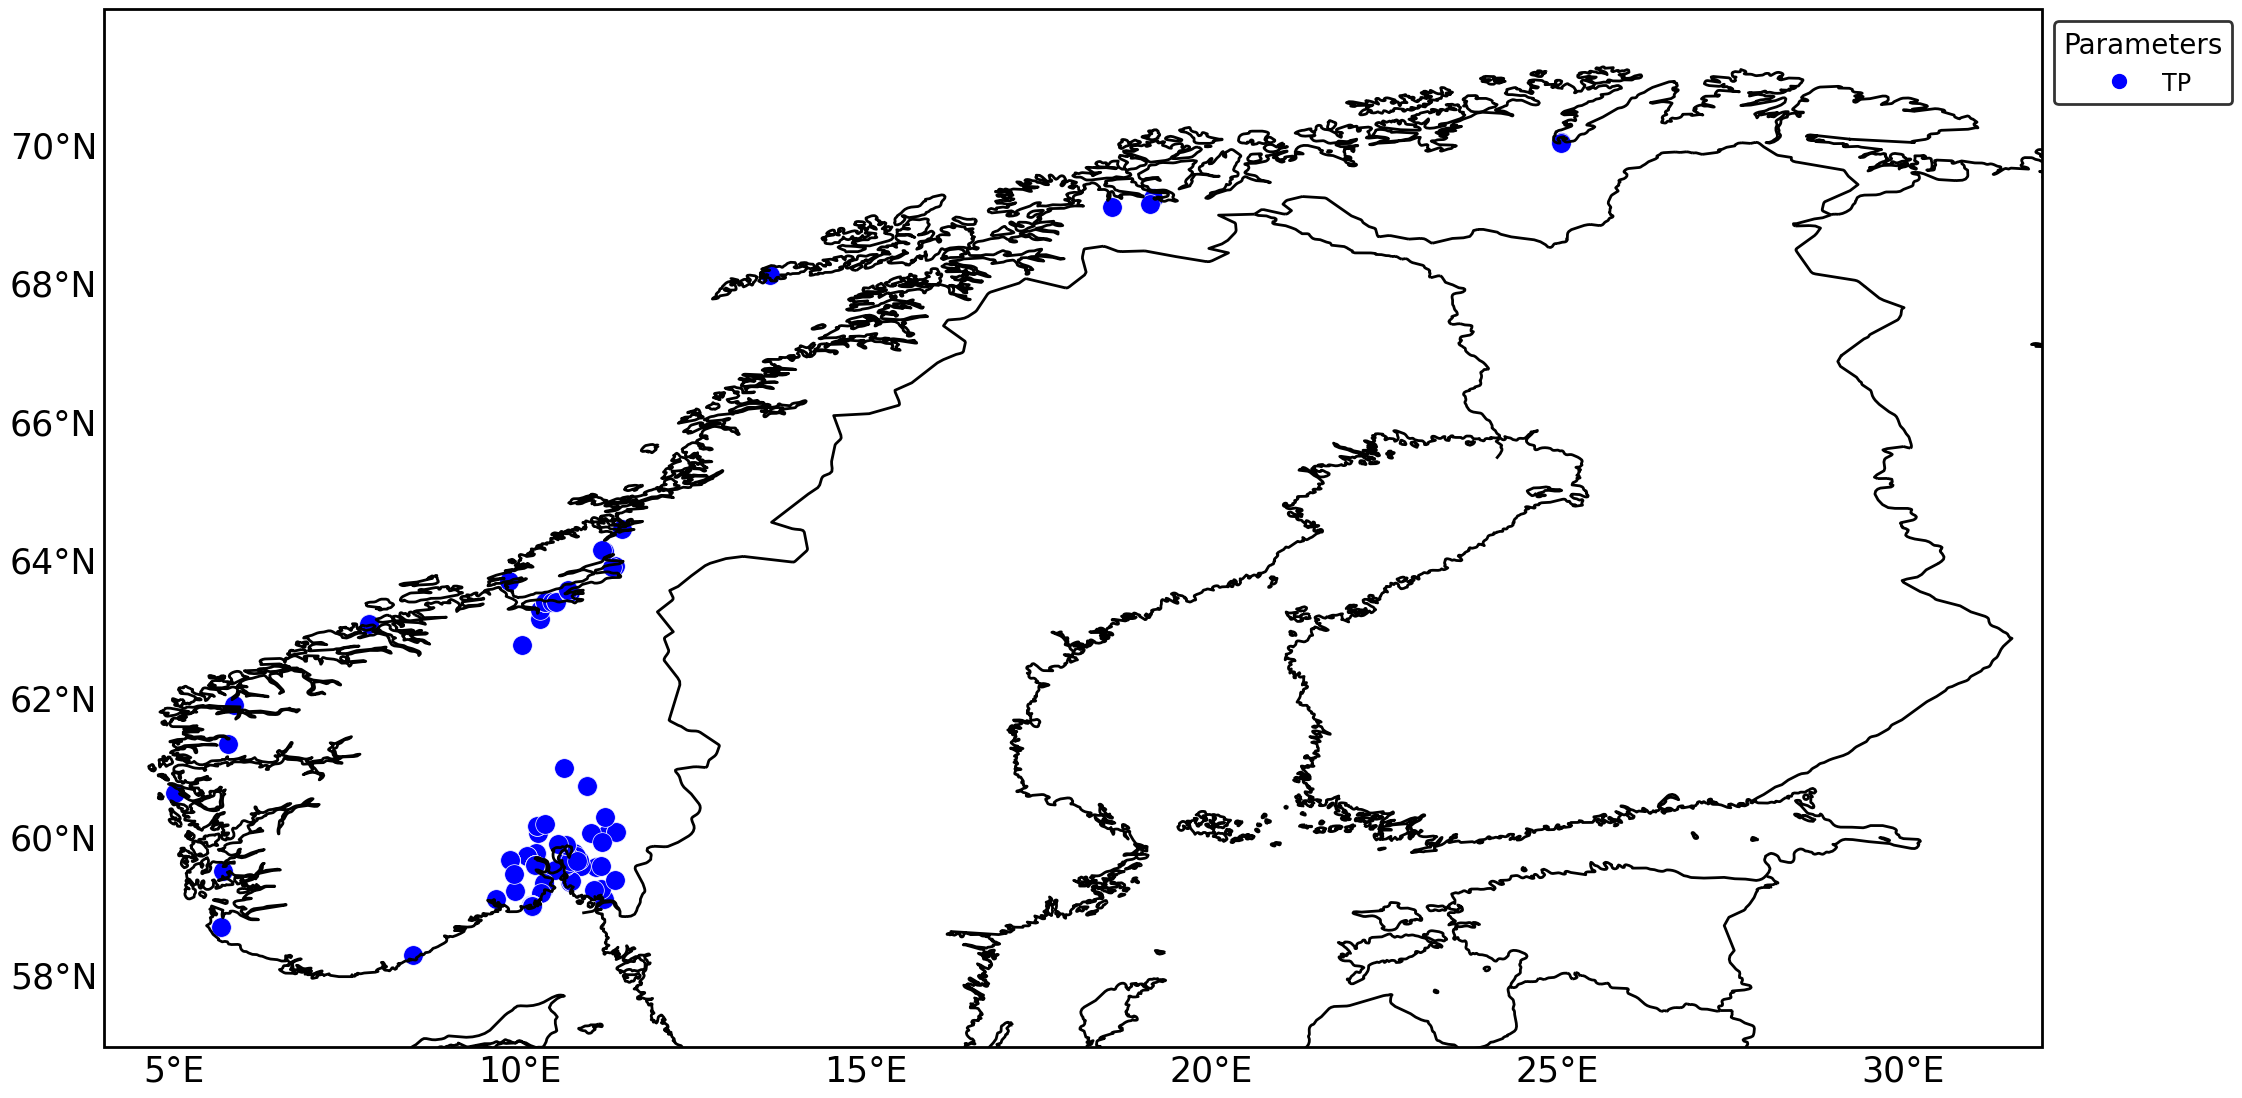

In [13]:
plot_map(filtered_df_iii, plot_variables='TP')

### 4. Sites with TOC above thresholds

In [14]:
# Filter the dataframe based on the conditions
filtered_df_iv = df_R[(df_R['TOC_mg_l'] > 40) & df_R['TOC_mg_l'].notna()]

# Get the unique water location codes and their count
unique_codes_iv = list(filtered_df_iv['WaterLocationCode'].unique())
count_unique_codes_iv = len(unique_codes_iv)

print("Number of sites with suspicious data:", count_unique_codes_iv)
print(" ")
print("Water Location Codes with suspicious data:\n", unique_codes_iv)

Number of sites with suspicious data: 195
 
Water Location Codes with suspicious data:
 ['002-102145', '002-105980', '002-28960', '002-29666', '002-30576', '002-30578', '002-31104', '002-39349', '002-39350', '002-50944', '002-50954', '002-50959', '002-51447', '002-51448', '002-51474', '002-51498', '002-52001', '002-58709', '002-59028', '002-59172', '002-62165', '002-62166', '002-62167', '002-62168', '002-62914', '002-64069', '002-64075', '002-64430', '002-81355', '002-81359', '002-81363', '002-81684', '002-83895', '002-87942', '002-97207', '002-97341', '003-30664', '003-30691', '003-30718', '004-85439', '005-28243', '005-28244', '005-28245', '005-28247', '005-42441', '005-42444', '005-42447', '005-42449', '005-42450', '005-42461', '005-42462', '005-42463', '005-42464', '005-42465', '005-42484', '005-42523', '005-42537', '005-42541', '005-42542', '005-42543', '005-42546', '005-42547', '005-42550', '005-42551', '005-42552', '005-44198', '005-44199', '005-64212', '006-51735', '006-58048',

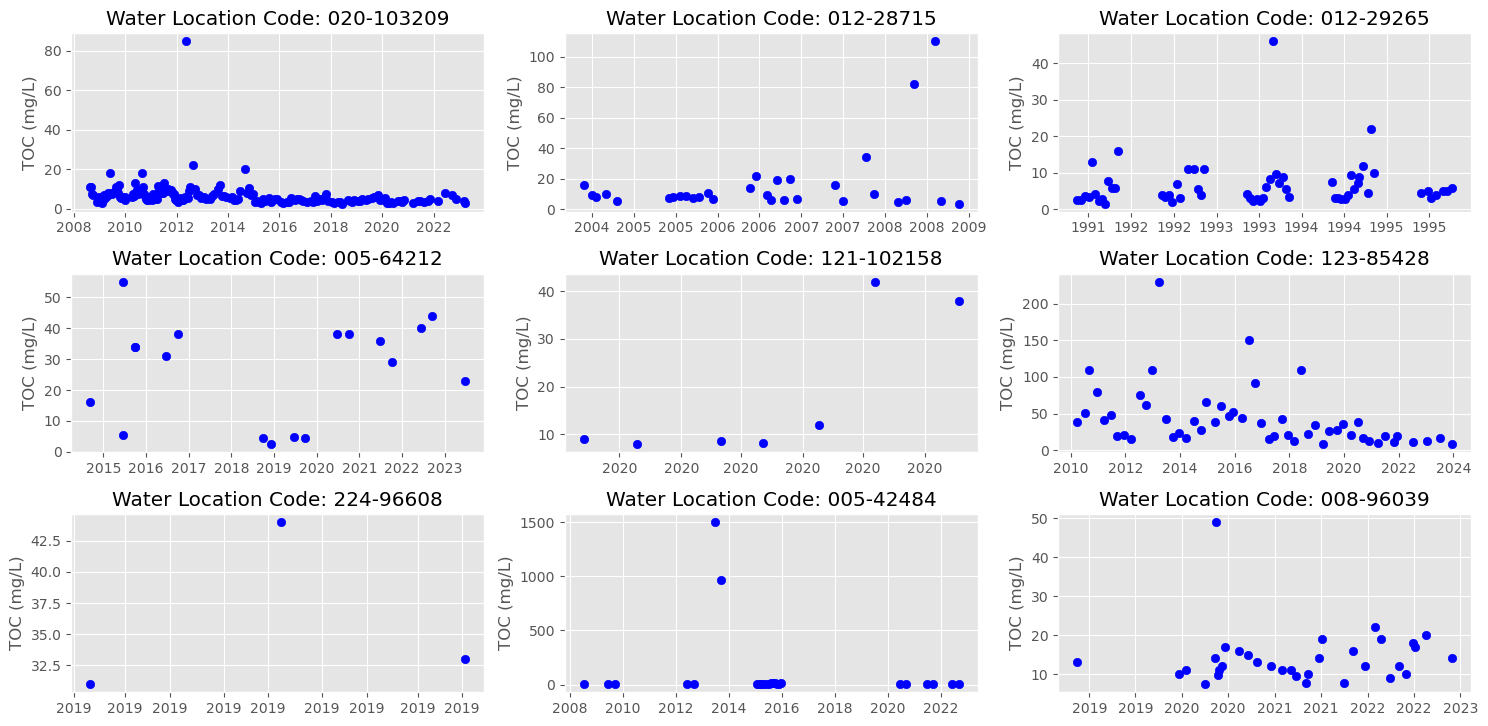

In [15]:
# Define a random list of WaterLocationCode values
random_sites = np.random.choice(unique_codes_iv, 9, replace=False)

with PdfPages('../plots/timeseries_plots_suspicious_tn.pdf') as pdf:
    # Create a figure with 2 columns and 3 rows
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 8))
       
    # Flatten the axes array for easy iteration
    axes = axes.flatten()
    
    # Iterate over each randomly selected WaterLocationCode
    for i, code in enumerate(random_sites):
        site_data = df_R[df_R['WaterLocationCode'] == code]
        
        # Plot TN
        axes[i].scatter(site_data['SamplingTime'], site_data['TOC_mg_l'], marker='o', color='blue')
        axes[i].set_title(f'Water Location Code: {code}')
        axes[i].set_ylabel('TOC (mg/L)')
        axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    # Adjust layout and save the figure to the PDF
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    pdf.savefig(fig)
    plt.show(fig)

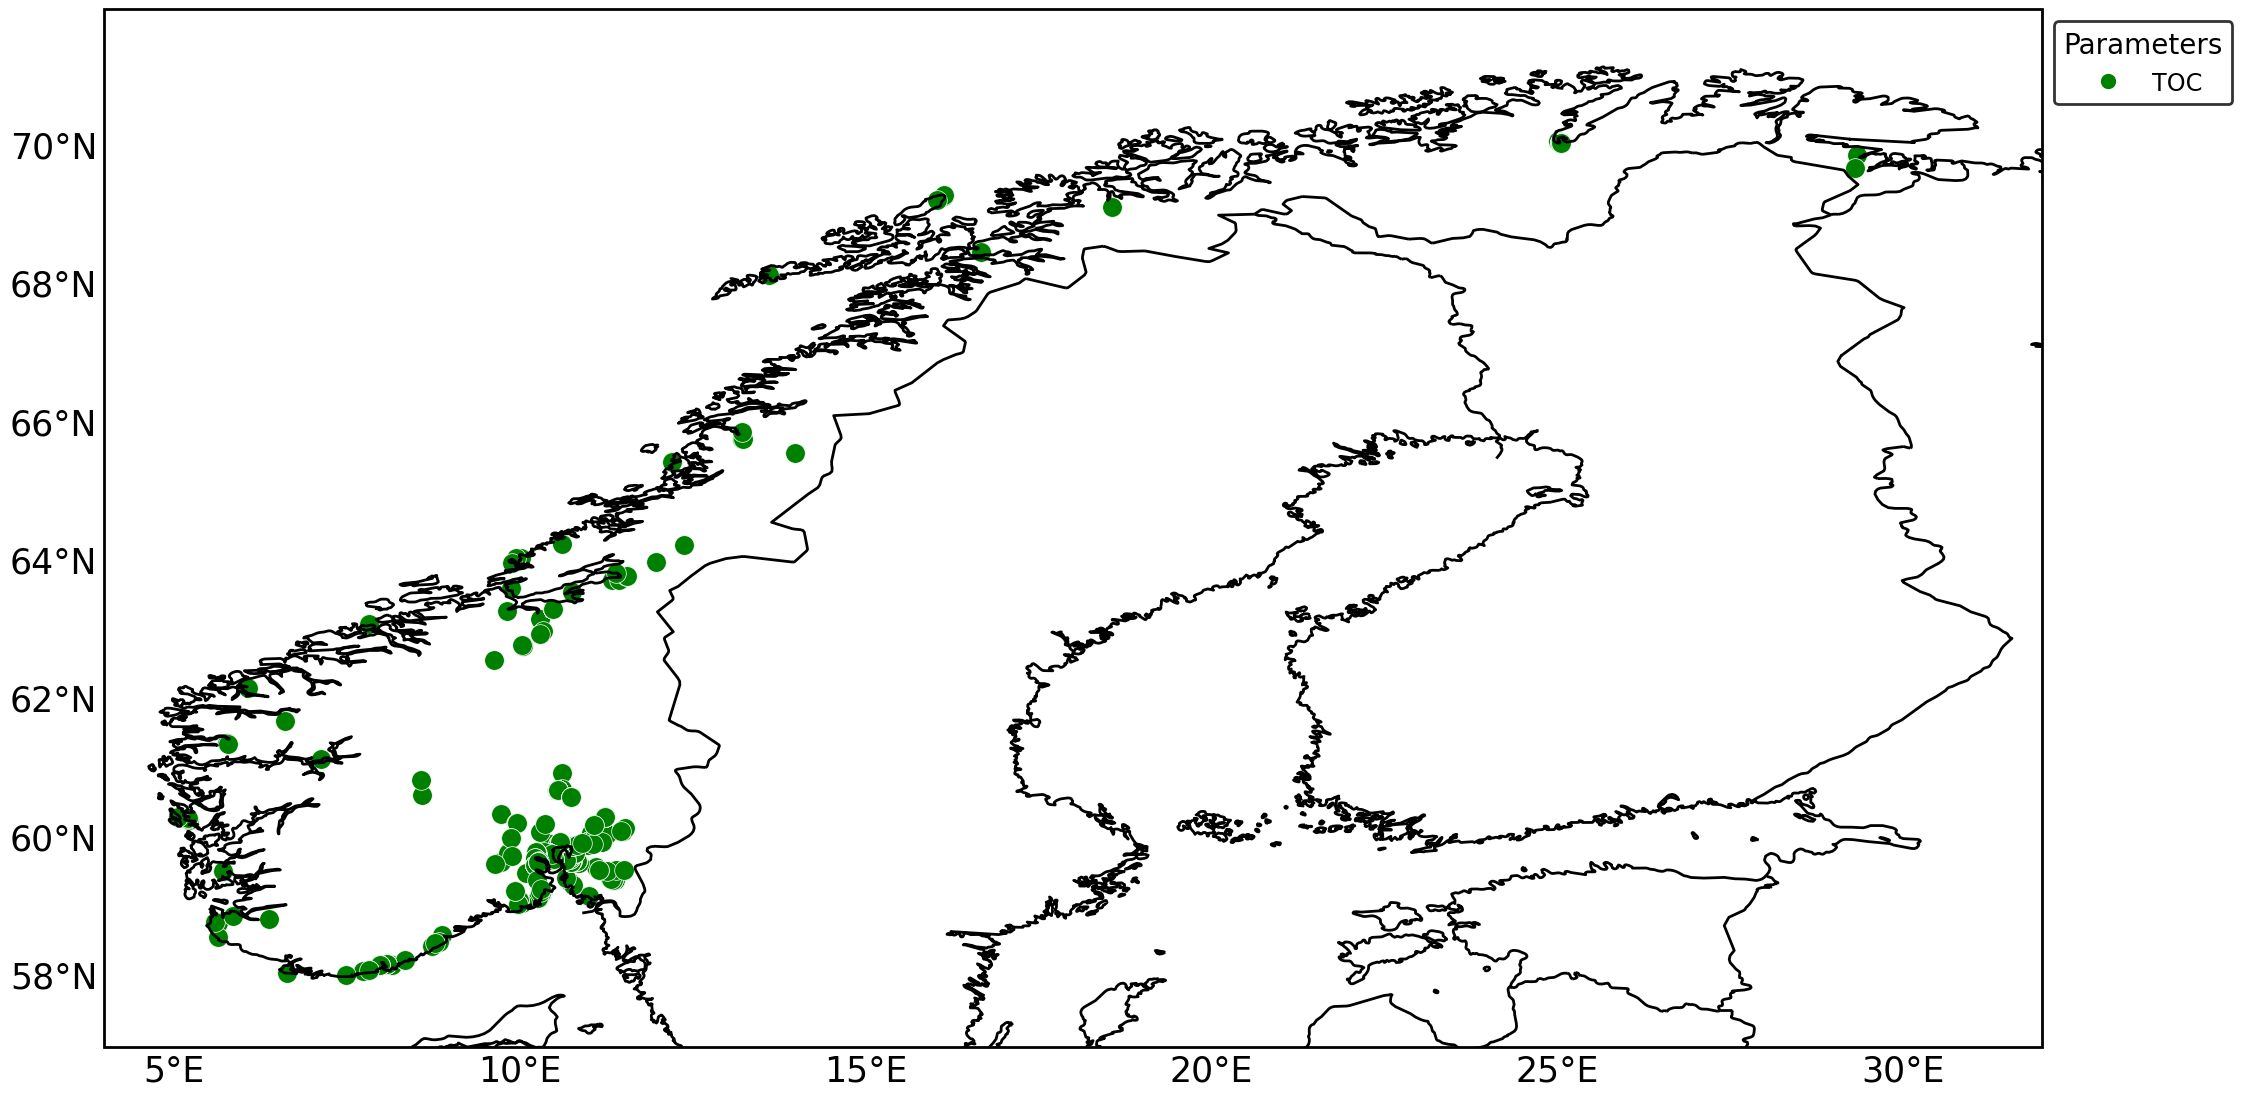

In [16]:
plot_map(filtered_df_iv, plot_variables='TOC')

## 5. Metadata of the sites with suspicious data 

In [17]:
# Read metadata file
meta_df = pd.read_csv("../data/raw_data/water_chemistry/ai_wc_metadata_2024.csv")
meta_df.keys()

Index(['Unnamed: 0', 'WaterLocationID', 'WaterLocationCode', 'CoordX',
       'CoordY', 'WaterCategory', 'Name', 'WaterBodyID', 'WaterBody',
       'Elevation', 'FeatureType', 'Fylke', 'Kommune', 'Vassdragsomrade',
       'Vannomrade', 'Vannregion', 'utm_zone', 'lat', 'lon'],
      dtype='object')

In [18]:
# Create a list with all sites with suspicious data
unique_codes_combined = set(unique_codes_ii + unique_codes_iii + unique_codes_iv)
unique_codes_list = list(unique_codes_combined)
# print("Combined unique water location codes:", unique_codes_list)
print("Number of unique water location codes:", len(unique_codes_combined))

# Filter the metadata dataframe
filtered_df_uq = meta_df[meta_df['WaterLocationCode'].isin(unique_codes_list)]
filtered_df_uq = filtered_df_uq.drop(columns=['Unnamed: 0'])

# Create columns
filtered_df_uq['suspicious TN'] = pd.NA
filtered_df_uq['suspicious TP'] = pd.NA
filtered_df_uq['suspicious TOC'] = pd.NA

# Flag which site has suspicious data for only for TN, TP, and TOC
filtered_df_uq['suspicious TN'] = filtered_df_uq['WaterLocationCode'].apply(lambda x: True if x in unique_codes_ii else False)
filtered_df_uq['suspicious TP'] = filtered_df_uq['WaterLocationCode'].apply(lambda x: True if x in unique_codes_iii else False)
filtered_df_uq['suspicious TOC'] = filtered_df_uq['WaterLocationCode'].apply(lambda x: True if x in unique_codes_iv else False)


Number of unique water location codes: 1168


In [19]:
filtered_df_uq

,WaterLocationID,WaterLocationCode,CoordX,CoordY,WaterCategory,Name,WaterBodyID,WaterBody,Elevation,FeatureType,...,Kommune,Vassdragsomrade,Vannomrade,Vannregion,utm_zone,lat,lon,suspicious TN,suspicious TP,suspicious TOC
26800,27864,002-27864,251395.9889,6.802726e+06,R,Kvamsbekken 1,002-4796-R,Kvamsbekken,NaN,point,...,Øyer,Glommavassdraget/Hvaler og Singlefjorden,Mjøsa,Innlandet og Viken,33,61.279239,10.360034,True,False,False
26814,27878,124-27878,293020.4401,7.046822e+06,R,Gråelva 3,NaN,NaN,NaN,point,...,Stjørdal,Stjørdalsvassdraget/Stjørdalsfjorden,Stjørdalsvassdraget,Trøndelag,33,63.489203,10.841844,True,False,False
26873,27942,003-27942,267659.8000,6.601274e+06,R,Veidalselva,003-129-R,Haugerelva - Kirkeelva - Veidalselva,26.0,point,...,Våler (Viken),Mossevassdraget/kyst Onsøy-Son,Morsa,Innlandet og Viken,33,59.485378,10.896369,True,False,False
26881,27953,003-27953,268372.2000,6.613507e+06,R,Kråkstadelva,003-131-R,Kråkstadelva,52.0,point,...,Indre Østfold,Mossevassdraget/kyst Onsøy-Son,Morsa,Innlandet og Viken,33,59.595340,10.895590,True,False,False
26899,27983,012-27983,222517.1101,6.607717e+06,R,Rønnebergelva ved Rønneberg,012-1330-R,Rønnebergelva/ Sundbyelva,0.0,point,...,Holmestrand,Drammensvassdraget/Drammensfjorden vest,Eikeren,Innlandet og Viken,33,59.515622,10.093785,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104168,106188,015-106188,215887.9900,6.559428e+06,R,Bekk fra Tiurleikåsene,NaN,NaN,0.0,point,...,Larvik,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Siljan - Farrisvassdraget,Vestfold og Telemark,33,59.079181,10.040510,False,False,True
104169,106189,015-106189,210771.4500,6.558179e+06,R,"Paulertjønn, bekk oppstrøms",015-1263-R,Paulertjern,0.0,point,...,Larvik,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Horten - Larvik,Vestfold og Telemark,33,59.064569,9.953237,True,False,False
104170,106190,015-106190,213372.5700,6.557915e+06,R,Anviksbekken,NaN,NaN,0.0,point,...,Larvik,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Siljan - Farrisvassdraget,Vestfold og Telemark,33,59.063963,9.998767,True,False,False
104176,106199,015-106199,215807.4300,6.559402e+06,R,"Ytretjønn, utløpsbekk",NaN,NaN,0.0,point,...,Larvik,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Siljan - Farrisvassdraget,Vestfold og Telemark,33,59.078898,10.039143,True,False,False


In [20]:
# Save metadata
filtered_df_uq.to_csv('../data/cleaned/water_chemistry/metadata_for_rivers_with_suspicious_data.csv', index=False)